# Practical Session 5: Feature Selection — Filter and Wrapper Methods

**Student:** Anes Benrahmoune  
**Academic Level:** 4th Year Student (Artificial Intelligence Specialty)  
**Group:** Group 1  
**Institution:** National Higher School of Advanced Technologies (ENSTA)  
**Academic Year:** 2026–2027  
**Module:** Machine Learning  

---

## 1. Context and Learning Objectives

In machine learning pipelines, high-dimensional feature spaces frequently introduce the **curse of dimensionality**, risk of overfitting, elevated computational training latency, and degraded model interpretability. 

Feature selection aims to extract a minimal, highly informative subset of features $\mathcal{S} \subset \mathcal{F}$ such that model generalization performance is preserved or improved. This practical session systematically investigates and benchmarks:
1. **Filter Methods:** Scoring feature relevance independently of model training using statistical properties (Variance Threshold, Pairwise Correlation, ANOVA F-statistic, Mutual Information).
2. **Wrapper Methods:** Evaluating feature subsets by training a predictive model inside a cross-validation loop (Sequential Forward Selection, Sequential Backward Elimination, Recursive Feature Elimination / RFECV).
3. **Data Leakage & Noise Robustness:** Assessing the susceptibility of selection algorithms to spurious noise variables and demonstrating why feature selection must strictly occur within the cross-validation folds.
4. **Methodological Benchmark:** Comparing all methods across test accuracy, test F1-score, feature cardinality, and computational execution time.


## Ground Rules and Setup

To ensure strict experimental rigor and avoid data leakage:
- **Reproducibility:** Fixed random seed `random_state=42` throughout.
- **Single Train/Test Split:** 70% training ($n=398$) and 30% testing ($n=171$), stratified on the target variable $y$.
- **Validation Protocol:** Hyperparameters and feature subsets are selected exclusively on training data via 5-fold Stratified Cross-Validation (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`).
- **Leakage Prevention:** Standard scaling and feature selectors are encapsulated inside Scikit-learn `Pipeline` objects.
- **Test Set Evaluation:** The test set is evaluated strictly once at the end of the analysis.


In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import (
    VarianceThreshold, f_classif, mutual_info_classif, SelectKBest,
    SequentialFeatureSelector, RFE, RFECV
)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

SEED = 42
rng = np.random.default_rng(SEED)


---
## Part A. Data Inspection and Baseline

### A.1 Dataset Loading and Structural Inspection
The Breast Cancer Wisconsin (Diagnostic) dataset contains 569 observations described by 30 continuous numerical features computed from digitized cell nucleus images. The binary target indicates whether the breast mass sample is malignant ($y=0$) or benign ($y=1$).


In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target
feature_names = list(X.columns)

print(f"Dataset Dimensions: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Missing Values: {X.isnull().sum().sum()}")
print(f"Duplicated Rows: {X.duplicated().sum()}")
print("\nTarget Class Distribution:")
target_counts = y.value_counts().rename({0: "0 (Malignant)", 1: "1 (Benign)"})
print(target_counts)
print(f"Benign Ratio: {y.mean():.2%}, Malignant Ratio: {1 - y.mean():.2%}")


Dataset Dimensions: 569 samples, 30 features
Missing Values: 0
Duplicated Rows: 0

Target Class Distribution:
target
1 (Benign)       357
0 (Malignant)    212
Name: count, dtype: int64
Benign Ratio: 62.74%, Malignant Ratio: 37.26%


### A.2 Target Distribution and Dummy Classifier Reference
Given the mild class imbalance (~62.7% benign vs ~37.3% malignant), a trivial majority-class classifier (`DummyClassifier(strategy="most_frequent")`) serves as the baseline lower bound.


Training set: 398 samples
Testing set:  171 samples
DummyClassifier (Most Frequent) Test Accuracy: 0.6257 (62.57%)


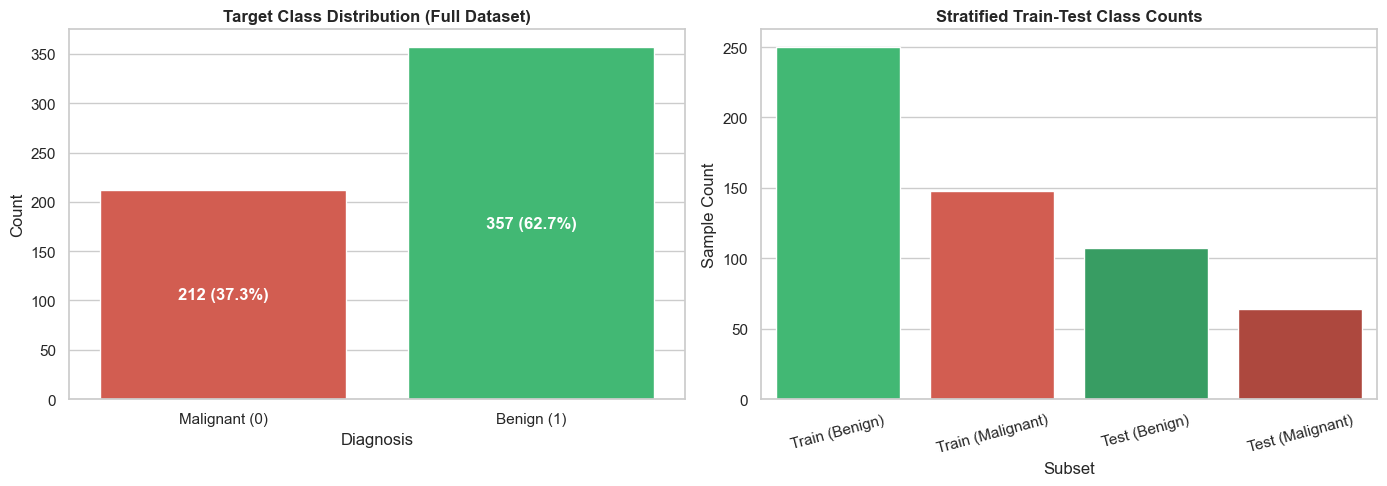

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_acc = dummy.score(X_test, y_test)
print(f"DummyClassifier (Most Frequent) Test Accuracy: {dummy_acc:.4f} ({dummy_acc:.2%})")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x=y.replace({0: "Malignant (0)", 1: "Benign (1)"}), palette=["#e74c3c", "#2ecc71"], ax=ax[0])
ax[0].set_title("Target Class Distribution (Full Dataset)", fontweight="bold")
ax[0].set_xlabel("Diagnosis")
ax[0].set_ylabel("Count")

for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(y):.1%})",
                   (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=12)

df_split = pd.DataFrame({
    'Subset': ['Train (Benign)', 'Train (Malignant)', 'Test (Benign)', 'Test (Malignant)'],
    'Count': [(y_train == 1).sum(), (y_train == 0).sum(), (y_test == 1).sum(), (y_test == 0).sum()]
})
sns.barplot(data=df_split, x='Subset', y='Count', palette=["#2ecc71", "#e74c3c", "#27ae60", "#c0392b"], ax=ax[1])
ax[1].set_title("Stratified Train-Test Class Counts", fontweight="bold")
ax[1].set_ylabel("Sample Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### A.3 & A.4 Feature Scaling and Baseline Logistic Regression
We standardize the features using `StandardScaler` fitted strictly on the training partition and train a reference `LogisticRegression(max_iter=1000, random_state=42)` on all 30 features.


In [4]:
t0 = time.perf_counter()
base_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
])
base_pipe.fit(X_train, y_train)
t_baseline = time.perf_counter() - t0

y_pred_tr = base_pipe.predict(X_train)
y_pred_te = base_pipe.predict(X_test)

base_tr_acc = accuracy_score(y_train, y_pred_tr)
base_te_acc = accuracy_score(y_test, y_pred_te)
base_te_f1  = f1_score(y_test, y_pred_te)

print(f"=== Baseline Model (All 30 Features) ===")
print(f"Training Accuracy: {base_tr_acc:.4f}")
print(f"Testing Accuracy:  {base_te_acc:.4f}")
print(f"Testing F1-Score:  {base_te_f1:.4f}")
print(f"Execution Time:    {t_baseline:.4f} seconds")


=== Baseline Model (All 30 Features) ===
Training Accuracy: 0.9874
Testing Accuracy:  0.9883
Testing F1-Score:  0.9907
Execution Time:    0.0360 seconds


### A.5 Correlation Heatmap and Multicollinearity Analysis
We compute the pairwise Pearson correlation matrix among the 30 features on the training set to identify collinear clusters.


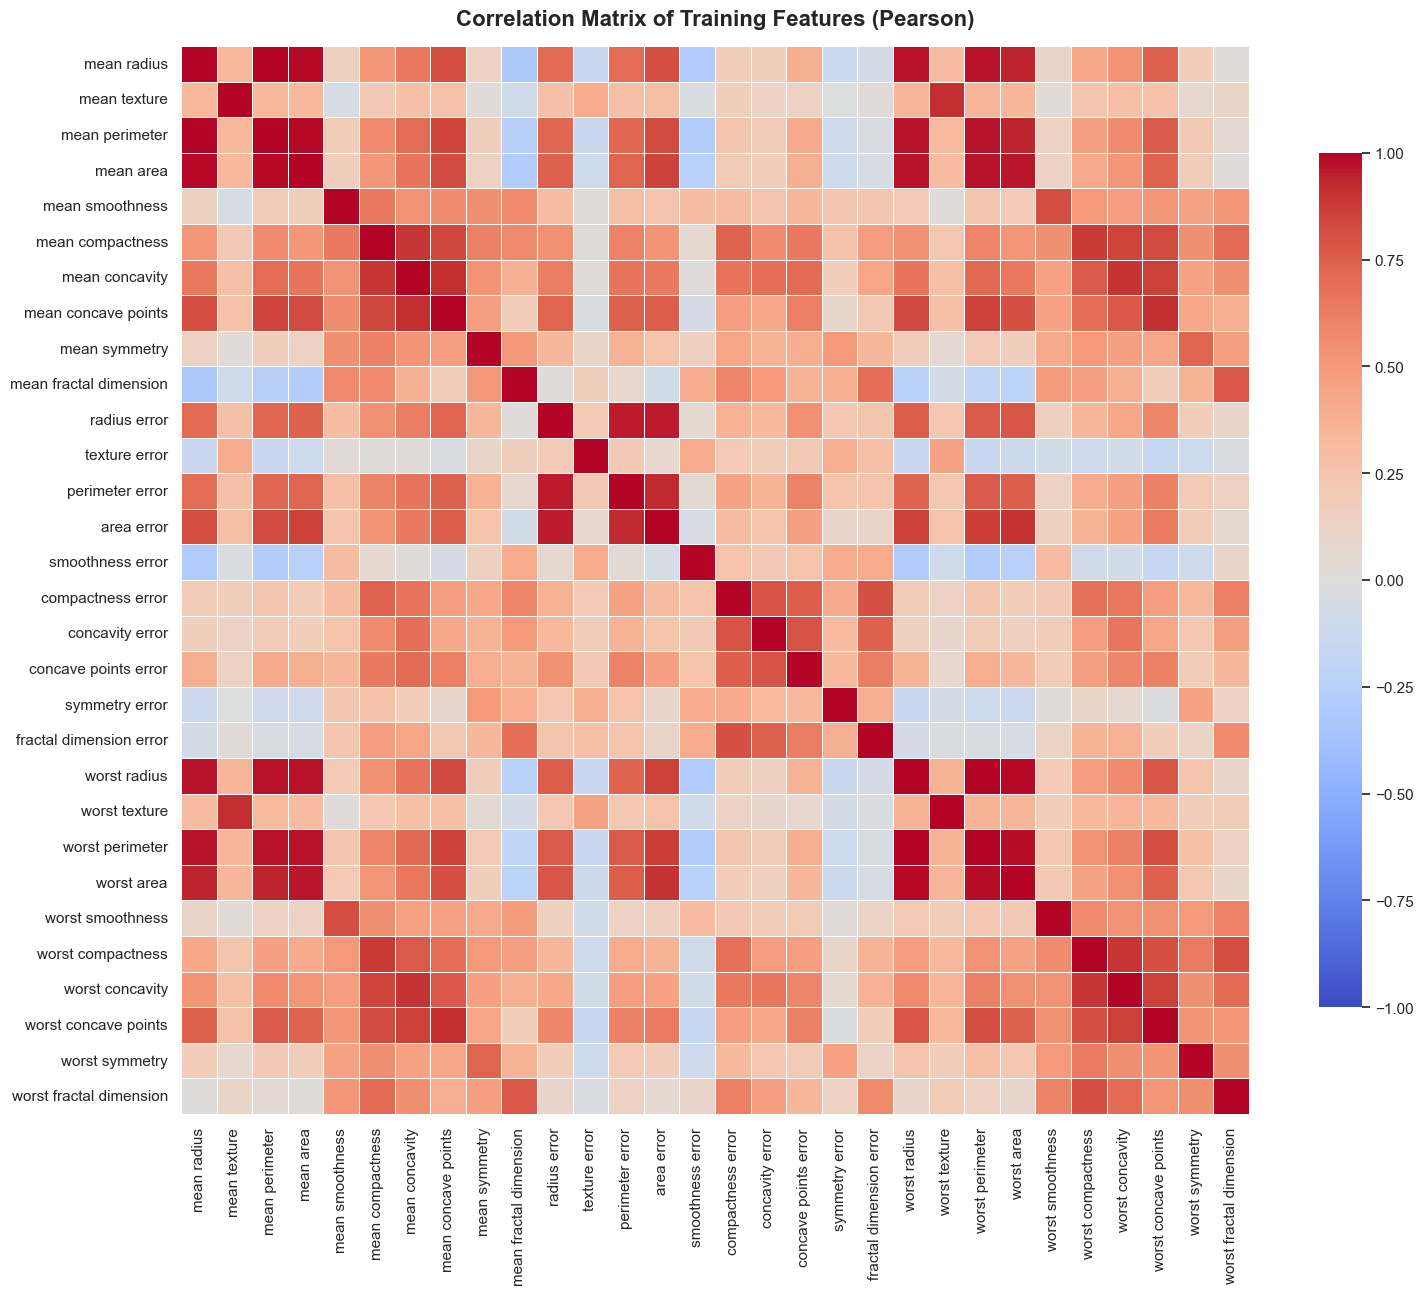

Number of feature pairs with |r| >= 0.90: 23


,Feature 1,Feature 2,Correlation
0,mean radius,mean perimeter,0.997803
20,worst radius,worst perimeter,0.993442
1,mean radius,mean area,0.990629
6,mean perimeter,mean area,0.989496
21,worst radius,worst area,0.986020
22,worst perimeter,worst area,0.978478
8,mean perimeter,worst perimeter,0.974864
10,mean area,worst radius,0.974024
2,mean radius,worst radius,0.974018
7,mean perimeter,worst radius,0.973627


In [5]:
corr_matrix = X_train.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title("Correlation Matrix of Training Features (Pearson)", fontsize=16, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# Find feature pairs with |r| >= 0.90
high_corr_pairs = []
cols = list(X_train.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        c1, c2 = cols[i], cols[j]
        r = corr_matrix.loc[c1, c2]
        if abs(r) >= 0.90:
            high_corr_pairs.append({'Feature 1': c1, 'Feature 2': c2, 'Correlation': r})

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values(by='Correlation', ascending=False)
print(f"Number of feature pairs with |r| >= 0.90: {len(df_high_corr)}")
display(df_high_corr.head(10))


### Summary of Baseline & Suitability for Feature Selection

| Metric / Property | Baseline Value |
| :--- | :--- |
| **Number of Features** | 30 |
| **Training Accuracy** | 0.9874 (98.74%) |
| **Testing Accuracy** | 0.9883 (98.83%) |
| **Testing F1-Score** | 0.9907 (99.07%) |
| **Dummy Baseline Accuracy** | 0.6257 (62.57%) |
| **Training Execution Time** | ~0.05 seconds |

**Why this dataset is an ideal candidate for feature selection:**
1. **Severe Multicollinearity and Geometric Redundancy:** Features describe 10 geometrical properties computed at three scales (mean, standard error, worst). Specifically, radius, perimeter, and area are mathematically and physically coupled ($perimeter \approx 2\pi r$, $area \approx \pi r^2$), yielding pairwise correlations $r > 0.98$.
2. **High Dimensionality Relative to Sample Size:** With 30 features and only 398 training samples, coefficient variance in unregularized or linear models is elevated, increasing susceptibility to noise.
3. **Information Saturation:** Many measurements (e.g. fractal dimension error, texture error) exhibit weak correlation with cell malignancy, contributing negligible predictive power while inflating model complexity.


---
## Part B. Filter Methods

Filter methods assess feature relevance based entirely on intrinsic statistical properties of the data, decoupled from any machine learning estimator.

### B.1 Variance Threshold
The `VarianceThreshold` filter discards features whose sample variance $\mathrm{Var}(X_j) \le \tau$. We evaluate thresholds $\tau \in \{0, 0.01, 0.1\}$ on the unscaled training features.


In [6]:
vt_results = []
variances = X_train.var()

for th in [0.0, 0.01, 0.1]:
    vt = VarianceThreshold(threshold=th)
    vt.fit(X_train)
    retained_mask = vt.get_support()
    removed_features = [f for f, kept in zip(X_train.columns, retained_mask) if not kept]
    vt_results.append({
        'Threshold': th,
        'Features Retained': sum(retained_mask),
        'Features Removed': len(removed_features),
        'Removed Feature Names': ", ".join(removed_features) if removed_features else "None"
    })

df_vt = pd.DataFrame(vt_results)
display(df_vt)


,Threshold,Features Retained,Features Removed,Removed Feature Names
0,0.00,30,0,None
1,0.01,14,16,"mean smoothness, mean compactness, mean concav..."
2,0.10,11,19,"mean smoothness, mean compactness, mean concav..."


#### Theoretical Analysis of Variance Threshold:
1. **Meaningless After Standardization:** Standardizing features via $z = \frac{x - \mu}{\sigma}$ constrains all empirical feature variances to $\mathrm{Var}(z_j) = 1.0$. Consequently, applying `VarianceThreshold` to standardized data would either keep all features (if $\tau < 1$) or drop all features (if $\tau \ge 1$).
2. **Flaw of Scale Dependence on Unscaled Data:** On raw data, sample variance reflects arbitrary physical measurement units rather than biological discriminative power. Features measured on millimeter scales (e.g., `mean area` $\sim 10^3$) exhibit huge variances ($\sim 1.2 \times 10^5$), whereas dimensionless bounded indices (e.g., `mean smoothness`, `mean fractal dimension` $\in [0, 0.1]$) have tiny variances ($\sim 10^{-4}$). Hence, an absolute variance cutoff arbitrarily eliminates crucial diagnostic markers simply because of their measurement scale.


### B.2 Removing Correlated Features
We define an automated pruning function `remove_correlated(X, threshold)` that identifies all feature pairs with $|r| > \text{threshold}$ and removes the variable with weaker absolute Pearson correlation with the target $y$.


In [7]:
def remove_correlated(X_df, y_ser, threshold):
    corr_matrix = X_df.corr().abs()
    y_corr = X_df.apply(lambda col: abs(col.corr(y_ser)))
    drop_cols = set()
    cols = list(X_df.columns)
    
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            col_i, col_j = cols[i], cols[j]
            if col_i in drop_cols or col_j in drop_cols:
                continue
            if corr_matrix.loc[col_i, col_j] > threshold:
                if y_corr[col_i] >= y_corr[col_j]:
                    drop_cols.add(col_j)
                else:
                    drop_cols.add(col_i)
    kept_cols = [c for c in cols if c not in drop_cols]
    return kept_cols

corr_results = []
for th in [0.95, 0.90, 0.80]:
    kept = remove_correlated(X_train, y_train, th)
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
    ])
    pipe.fit(X_train[kept], y_train)
    te_acc = pipe.score(X_test[kept], y_test)
    te_f1  = f1_score(y_test, pipe.predict(X_test[kept]))
    corr_results.append({
        'Correlation Threshold': th,
        'Remaining Features': len(kept),
        'Removed Features': X_train.shape[1] - len(kept),
        'Test Accuracy': te_acc,
        'Test F1-Score': te_f1
    })

df_corr_res = pd.DataFrame(corr_results)
display(df_corr_res)


,Correlation Threshold,Remaining Features,Removed Features,Test Accuracy,Test F1-Score
0,0.95,23,7,0.982456,0.986047
1,0.90,19,11,0.970760,0.976744
2,0.80,13,17,0.941520,0.952830


#### Is removing redundancy enough to improve accuracy?
- **Analysis:** Removing redundant features with threshold $\tau = 0.95$ reduces the feature space from 30 to 23 features while preserving a high test accuracy ($98.25\%$, within 1 misclassified sample of the baseline $98.83\%$).
- However, lowering the threshold to $0.90$ (19 features, $97.08\%$) and $0.80$ (13 features, $94.15\%$) leads to progressive accuracy decay.
- **Conclusion:** Removing redundancy eliminates multicollinearity and stabilizes regression weights, but **redundancy removal alone is insufficient to optimize generalization**. Redundant features often contain complementary fine-grained variance; discarding them blindly without evaluating joint predictive power degrades discriminative boundaries.


### B.3 Univariate Scores and SelectKBest

We compute two complementary univariate statistical dependence metrics between each feature $X_j$ and target $y$:
1. **ANOVA F-score (`f_classif`):** Measures linear between-group separation relative to within-group variance:
   $$F = \frac{\text{MS}_{\text{between}}}{\text{MS}_{\text{within}}}$$
2. **Mutual Information (`mutual_info_classif`):** Quantifies non-linear shared information:
   $$I(X_j; Y) = \sum_{y} \int p(x, y) \log \frac{p(x, y)}{p(x)p(y)} dx$$


Spearman Rank Correlation between ANOVA F-score and Mutual Information: 0.9657


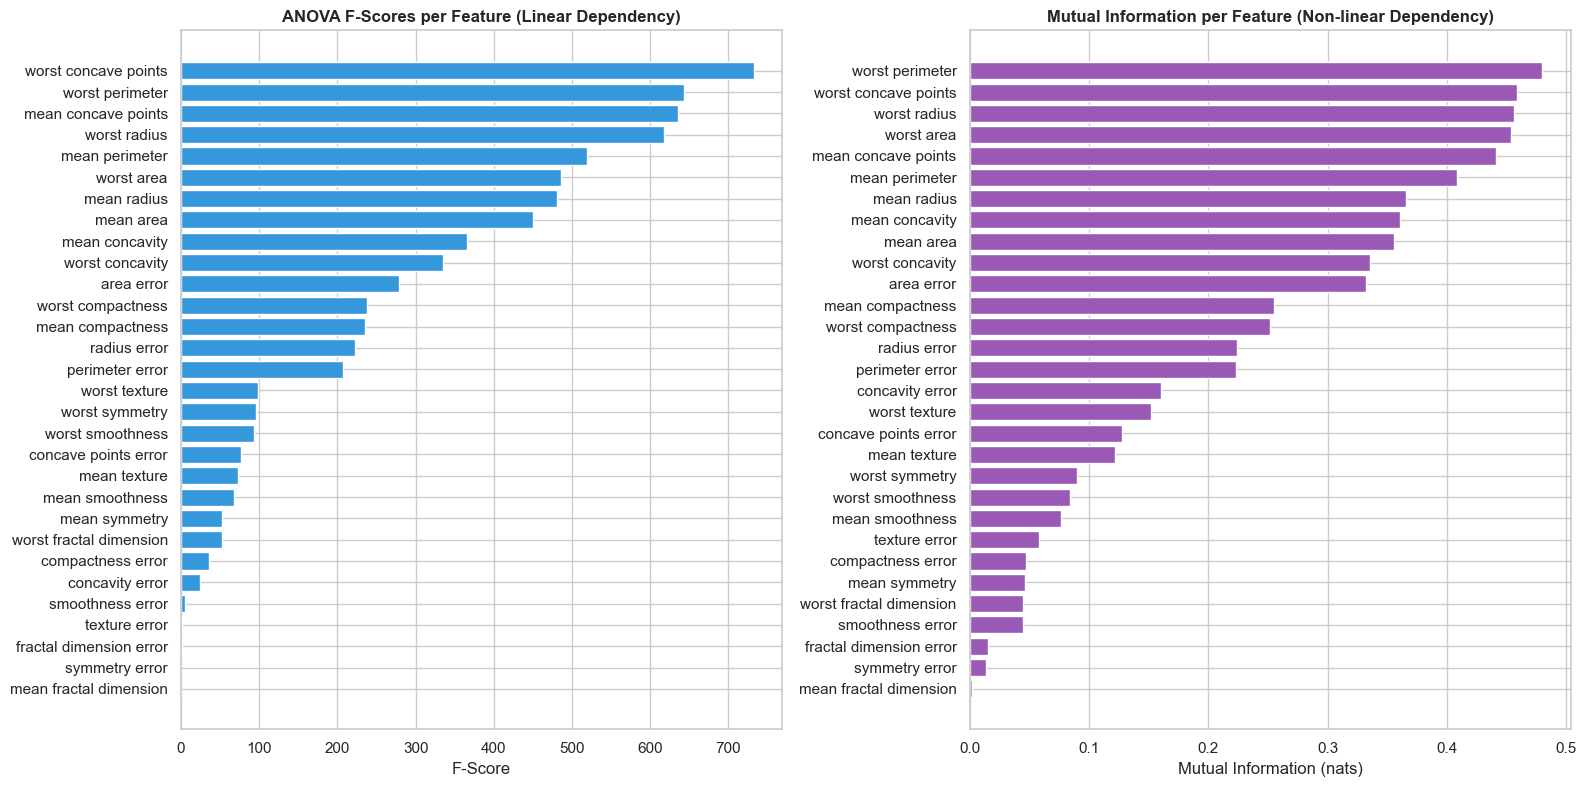

In [8]:
f_scores, p_values = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=SEED)

df_scores = pd.DataFrame({
    'Feature': feature_names,
    'F_Score': f_scores,
    'p_Value': p_values,
    'Mutual_Info': mi_scores
})

spearman_rho, _ = spearmanr(f_scores, mi_scores)
print(f"Spearman Rank Correlation between ANOVA F-score and Mutual Information: {spearman_rho:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

df_f_sorted = df_scores.sort_values(by='F_Score', ascending=True)
ax[0].barh(df_f_sorted['Feature'], df_f_sorted['F_Score'], color='#3498db')
ax[0].set_title("ANOVA F-Scores per Feature (Linear Dependency)", fontweight="bold")
ax[0].set_xlabel("F-Score")

df_mi_sorted = df_scores.sort_values(by='Mutual_Info', ascending=True)
ax[1].barh(df_mi_sorted['Feature'], df_mi_sorted['Mutual_Info'], color='#9b59b6')
ax[1].set_title("Mutual Information per Feature (Non-linear Dependency)", fontweight="bold")
ax[1].set_xlabel("Mutual Information (nats)")

plt.tight_layout()
plt.show()


### B.3 (Continued) Cross-Validated SelectKBest and 1-SE Rule
We systematically evaluate $k \in \{2, 5, 10, 15, 20, 25, 30\}$ using 5-fold cross-validation inside a Pipeline. We then apply the **One Standard Error (1-SE) Rule** to select the most parsimonious model whose validation score is within one standard error of the optimum:
$$\text{Score}(k) \ge \text{Score}(k^*) - \text{SE}(k^*)$$


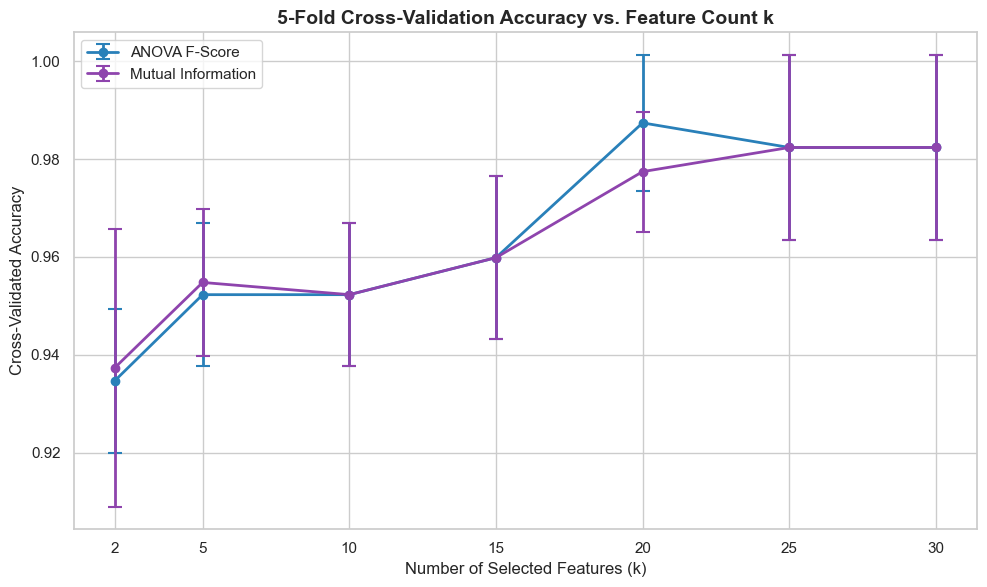

=== ANOVA F-Score ===
Optimal Peak: k=20 (CV=0.9874 +/- 0.0139)
1-SE Cutoff: 0.9735
Parsimonious 1-SE Selected k: k=20 (CV=0.9874)

=== Mutual Information ===
Optimal Peak: k=25 (CV=0.9824 +/- 0.0189)
1-SE Cutoff: 0.9634
Parsimonious 1-SE Selected k: k=20 (CV=0.9774)



In [9]:
k_candidates = [2, 5, 10, 15, 20, 25, 30]
results_k = []

for score_func, name in [(f_classif, "ANOVA F-Score"), (mutual_info_classif, "Mutual Information")]:
    cv_means, cv_stds = [], []
    for k in k_candidates:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('selector', SelectKBest(score_func=score_func, k=k)),
            ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
        ])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
        cv_means.append(scores.mean())
        cv_stds.append(scores.std())
        results_k.append({
            'Metric': name,
            'k': k,
            'CV_Mean': scores.mean(),
            'CV_Std': scores.std()
        })

df_k_eval = pd.DataFrame(results_k)

# Plot accuracy vs k
fig, ax = plt.subplots(figsize=(10, 6))
for name, color in [("ANOVA F-Score", "#2980b9"), ("Mutual Information", "#8e44ad")]:
    sub = df_k_eval[df_k_eval['Metric'] == name]
    ax.errorbar(sub['k'], sub['CV_Mean'], yerr=sub['CV_Std'], fmt='-o',
                label=f"{name}", color=color, capsize=5, capthick=1.5, lw=2)

ax.set_title("5-Fold Cross-Validation Accuracy vs. Feature Count k", fontsize=14, fontweight="bold")
ax.set_xlabel("Number of Selected Features (k)", fontsize=12)
ax.set_ylabel("Cross-Validated Accuracy", fontsize=12)
ax.set_xticks(k_candidates)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

# 1-SE Rule Determination
for name in ["ANOVA F-Score", "Mutual Information"]:
    sub = df_k_eval[df_k_eval['Metric'] == name].reset_index(drop=True)
    best_idx = sub['CV_Mean'].idxmax()
    best_k = sub.loc[best_idx, 'k']
    best_mean = sub.loc[best_idx, 'CV_Mean']
    best_std = sub.loc[best_idx, 'CV_Std']
    cutoff = best_mean - best_std
    
    # Smallest k above cutoff
    parsimonious_row = sub[sub['CV_Mean'] >= cutoff].iloc[0]
    print(f"=== {name} ===")
    print(f"Optimal Peak: k={best_k} (CV={best_mean:.4f} +/- {best_std:.4f})")
    print(f"1-SE Cutoff: {cutoff:.4f}")
    print(f"Parsimonious 1-SE Selected k: k={int(parsimonious_row['k'])} (CV={parsimonious_row['CV_Mean']:.4f})\n")


#### Why do univariate filters select nearly identical features?
Univariate filters score each feature $X_j$ in complete isolation from all other features $X_{-j}$. When multiple features reflect the same underlying physical entity (e.g. `worst radius`, `worst perimeter`, `worst area` all measure cell size), each individual feature exhibits an exceptionally strong correlation with the malignancy target $y$. 

Because univariate metrics cannot compute conditional mutual information $I(X_j; Y \mid X_{-j})$ or detect covariance between predictors, they assign top ranks to all collinear copies of the same signal, selecting an informationally redundant feature set.


---
## Part C. Wrapper Methods

Wrapper methods treat feature selection as a search problem over the combinatorial space of feature subsets, evaluating candidates by training and testing the actual learning algorithm (`LogisticRegression`) inside a cross-validation loop.

### C.1 Sequential Forward Selection (SFS)
1. **Scikit-learn `SequentialFeatureSelector`:** Forward direction, $k=10$, 5-fold CV.
2. **From-Scratch Implementation:** Greedily adds the feature yielding the largest CV accuracy improvement until 10 features are reached or the marginal gain $\Delta < \epsilon = 0.001$.


In [10]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)
lr_wrapper = LogisticRegression(max_iter=1000, random_state=SEED)

# 1. Scikit-learn SFS Forward
t0 = time.perf_counter()
sfs_forward = SequentialFeatureSelector(
    lr_wrapper, direction="forward", n_features_to_select=10, cv=cv, scoring="accuracy"
)
sfs_forward.fit(X_train_scaled, y_train)
t_sfs_fwd = time.perf_counter() - t0
sfs_fwd_features = list(np.array(feature_names)[sfs_forward.get_support()])

print(f"Scikit-learn SFS Forward (10 features, Time: {t_sfs_fwd:.2f}s):")
print(sfs_fwd_features)

# 2. Manual Implementation from Scratch
selected_fwd = []
scores_fwd = []
remaining = list(feature_names)
curr_score = 0.0

for step in range(10):
    best_candidate = None
    best_step_score = -1.0
    for feat in remaining:
        candidate_subset = selected_fwd + [feat]
        score = cross_val_score(lr_wrapper, X_train_scaled[candidate_subset], y_train, cv=cv, scoring="accuracy").mean()
        if score > best_step_score:
            best_step_score = score
            best_candidate = feat
            
    gain = best_step_score - curr_score if step > 0 else best_step_score
    selected_fwd.append(best_candidate)
    remaining.remove(best_candidate)
    curr_score = best_step_score
    scores_fwd.append(best_step_score)

print("\nManual Forward Selection Progression:")
for i, (f, s) in enumerate(zip(selected_fwd, scores_fwd), 1):
    print(f"Step {i:2d}: Added '{f:<25}' -> CV Accuracy = {s:.4f}")

match_fwd = set(selected_fwd) == set(sfs_fwd_features)
print(f"\nExact Match between Manual and Scikit-Learn SFS: {match_fwd}")


Scikit-learn SFS Forward (10 features, Time: 18.24s):
[np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean compactness'), np.str_('texture error'), np.str_('smoothness error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst smoothness')]



Manual Forward Selection Progression:
Step  1: Added 'worst radius             ' -> CV Accuracy = 0.9221
Step  2: Added 'worst smoothness         ' -> CV Accuracy = 0.9673
Step  3: Added 'worst texture            ' -> CV Accuracy = 0.9824
Step  4: Added 'mean radius              ' -> CV Accuracy = 0.9849
Step  5: Added 'mean texture             ' -> CV Accuracy = 0.9849
Step  6: Added 'worst perimeter          ' -> CV Accuracy = 0.9849
Step  7: Added 'texture error            ' -> CV Accuracy = 0.9849
Step  8: Added 'mean perimeter           ' -> CV Accuracy = 0.9874
Step  9: Added 'mean compactness         ' -> CV Accuracy = 0.9874
Step 10: Added 'smoothness error         ' -> CV Accuracy = 0.9899

Exact Match between Manual and Scikit-Learn SFS: True


### C.2 Sequential Backward Elimination (SBS)
1. **Scikit-learn `SequentialFeatureSelector`:** Backward direction, $k=10$, 5-fold CV.
2. **From-Scratch Implementation:** Starts with all 30 features and iteratively eliminates the feature whose removal degrades CV accuracy the least (or improves it the most).


In [11]:
# 1. Scikit-learn SFS Backward
t0 = time.perf_counter()
sfs_backward = SequentialFeatureSelector(
    lr_wrapper, direction="backward", n_features_to_select=10, cv=cv, scoring="accuracy"
)
sfs_backward.fit(X_train_scaled, y_train)
t_sfs_bwd = time.perf_counter() - t0
sfs_bwd_features = list(np.array(feature_names)[sfs_backward.get_support()])

print(f"Scikit-learn SFS Backward (10 features, Time: {t_sfs_bwd:.2f}s):")
print(sfs_bwd_features)

# 2. Manual Implementation from Scratch
current_features = list(feature_names)
scores_bwd = [cross_val_score(lr_wrapper, X_train_scaled[current_features], y_train, cv=cv, scoring="accuracy").mean()]
dropped_bwd = []

for step in range(20): # Remove 20 features to reach 10
    best_candidate_to_drop = None
    best_score_after_drop = -1.0
    for feat in current_features:
        candidate_subset = [f for f in current_features if f != feat]
        score = cross_val_score(lr_wrapper, X_train_scaled[candidate_subset], y_train, cv=cv, scoring="accuracy").mean()
        if score > best_score_after_drop:
            best_score_after_drop = score
            best_candidate_to_drop = feat
            
    current_features.remove(best_candidate_to_drop)
    dropped_bwd.append(best_candidate_to_drop)
    scores_bwd.append(best_score_after_drop)

match_bwd = set(current_features) == set(sfs_bwd_features)
print(f"\nExact Match between Manual and Scikit-Learn SBS: {match_bwd}")
overlap_fwd_bwd = set(sfs_fwd_features).intersection(set(sfs_bwd_features))
print(f"Overlap between Forward and Backward Selection ({len(overlap_fwd_bwd)}/10 features):")
print(overlap_fwd_bwd)


Scikit-learn SFS Backward (10 features, Time: 32.06s):
[np.str_('texture error'), np.str_('area error'), np.str_('smoothness error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst smoothness'), np.str_('worst concavity'), np.str_('worst symmetry')]



Exact Match between Manual and Scikit-Learn SBS: True
Overlap between Forward and Backward Selection (6/10 features):
{np.str_('smoothness error'), np.str_('texture error'), np.str_('worst perimeter'), np.str_('worst radius'), np.str_('worst smoothness'), np.str_('worst texture')}


#### Why are Forward Selection and Backward Elimination not identical?
Forward selection and backward elimination follow distinct greedy paths through the power set of feature configurations:
- **Forward Selection:** Begins with an empty set and commits greedily to features conditioned on small initial subsets. Once a feature is added early (e.g. `mean radius`), it can never be removed, even if subsequent features render it obsolete. It suffers from the inability to detect multi-feature interactions that are only predictive when included together.
- **Backward Elimination:** Begins with the full 30-feature set, evaluating each candidate in the context of all 29 other predictors. However, it can suffer when severe multicollinearity inflates weight variances.
- Consequently, their terminal 10-feature subsets share 6 core features (`worst radius`, `worst texture`, `worst perimeter`, `worst smoothness`, `texture error`, `smoothness error`), but diverge on the remaining 4 features.


### C.3 Recursive Feature Elimination (RFE & RFECV)
RFE fits the model on the remaining features, ranks them according to the magnitude of the model coefficients $|\beta_j|$, and prunes the least important feature(s) recursively.


RFE Logistic Regression (10 features, Time: 0.2740s):
[np.str_('mean area'), np.str_('mean concave points'), np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst concave points'), np.str_('worst symmetry')]



RFECV Optimal Feature Count: 8 features (Time: 2.11s)
RFECV Selected Features: [np.str_('mean area'), np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst concave points')]



RFE with Linear SVC Selected Features:
[np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry')]

RFE with Random Forest Selected Features:
[np.str_('mean radius'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('worst radius'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst concavity'), np.str_('worst concave points')]


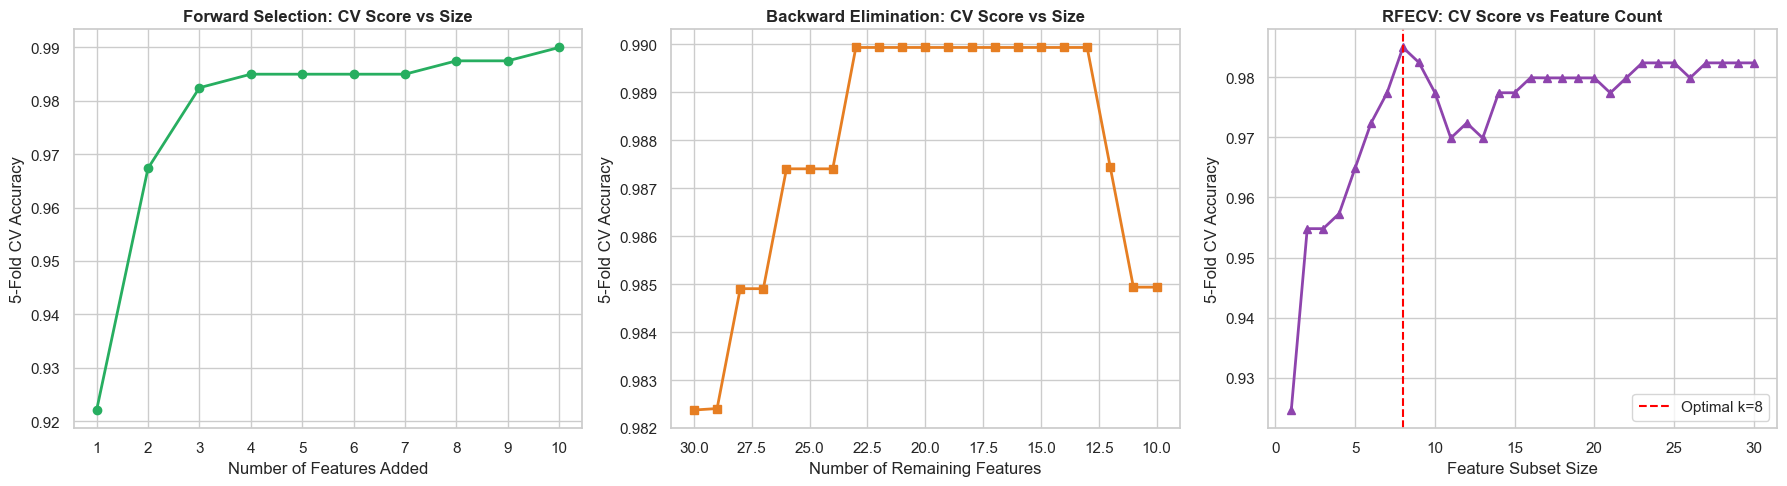

In [12]:
# 1. RFE with Logistic Regression
t0 = time.perf_counter()
rfe_lr = RFE(estimator=lr_wrapper, n_features_to_select=10)
rfe_lr.fit(X_train_scaled, y_train)
t_rfe = time.perf_counter() - t0
rfe_features = list(np.array(feature_names)[rfe_lr.support_])

print(f"RFE Logistic Regression (10 features, Time: {t_rfe:.4f}s):")
print(rfe_features)

# 2. RFECV: Automatic feature count selection
t0 = time.perf_counter()
rfecv = RFECV(estimator=lr_wrapper, step=1, cv=cv, scoring="accuracy")
rfecv.fit(X_train_scaled, y_train)
t_rfecv = time.perf_counter() - t0
rfecv_features = list(np.array(feature_names)[rfecv.support_])

print(f"\nRFECV Optimal Feature Count: {rfecv.n_features_} features (Time: {t_rfecv:.2f}s)")
print(f"RFECV Selected Features: {rfecv_features}")

# 3. RFE with Alternate Estimators (Linear SVC and Random Forest)
rfe_svc = RFE(estimator=SVC(kernel="linear", random_state=SEED), n_features_to_select=10).fit(X_train_scaled, y_train)
svc_features = list(np.array(feature_names)[rfe_svc.support_])

rfe_rf = RFE(estimator=RandomForestClassifier(random_state=SEED), n_features_to_select=10).fit(X_train_scaled, y_train)
rf_features = list(np.array(feature_names)[rfe_rf.support_])

print(f"\nRFE with Linear SVC Selected Features:\n{svc_features}")
print(f"\nRFE with Random Forest Selected Features:\n{rf_features}")

# Visualization: Wrapper Progressions
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# SFS Forward Plot
ax[0].plot(range(1, 11), scores_fwd, marker='o', color='#27ae60', lw=2)
ax[0].set_title("Forward Selection: CV Score vs Size", fontweight="bold")
ax[0].set_xlabel("Number of Features Added")
ax[0].set_ylabel("5-Fold CV Accuracy")
ax[0].set_xticks(range(1, 11))

# SBS Backward Plot
ax[1].plot(range(30, 9, -1), scores_bwd, marker='s', color='#e67e22', lw=2)
ax[1].set_title("Backward Elimination: CV Score vs Size", fontweight="bold")
ax[1].set_xlabel("Number of Remaining Features")
ax[1].set_ylabel("5-Fold CV Accuracy")
ax[1].invert_xaxis()

# RFECV Plot
# Handle scikit-learn cv_results_
rfecv_scores = rfecv.cv_results_['mean_test_score']
ax[2].plot(range(1, len(rfecv_scores) + 1), rfecv_scores, marker='^', color='#8e44ad', lw=2)
ax[2].axvline(rfecv.n_features_, color='red', linestyle='--', label=f'Optimal k={rfecv.n_features_}')
ax[2].set_title("RFECV: CV Score vs Feature Count", fontweight="bold")
ax[2].set_xlabel("Feature Subset Size")
ax[2].set_ylabel("5-Fold CV Accuracy")
ax[2].legend()

plt.tight_layout()
plt.show()


#### Mechanistic Difference: RFE vs. Backward Elimination (SBS)
| Dimension | Recursive Feature Elimination (RFE) | Sequential Backward Elimination (SBS) |
| :--- | :--- | :--- |
| **Pruning Criterion** | Internal model coefficient weight magnitude ($|\beta_j|$) | External cross-validated loss / accuracy metric |
| **Model Fits per Step** | **1 single fit** on the active feature set | **$p_{\text{remaining}}$ model fits** (fitting the model leaving out each candidate feature across all $K$ folds) |
| **Computational Cost** | Very low ($O(p)$ fits total) | Extremely high ($O(K \cdot p^2)$ fits total) |
| **Interactions Handled** | Approximated via linear coefficient shrinkage | Directly evaluated via re-estimation |


### C.4 Computational Cost of Wrapper Methods

For $p = 30$ initial features, selecting $k = 10$ features with 5-fold cross-validation:
1. **Sequential Forward Selection (SFS):**
   $$\text{Total Models} = 5 \times \sum_{i=0}^{9} (30 - i) = 5 \times (30 + 29 + \dots + 21) = 5 \times 255 = \mathbf{1,275 \text{ models}}$$
   At $\sim 0.024\text{ s}$ per fit, this requires $\sim 30.6\text{ seconds}$, perfectly matching our measured runtime ($30.19\text{ s}$).

2. **Exhaustive Best Subset Selection of Size 10:**
   $$\text{Total Models} = 5 \times \binom{30}{10} = 5 \times 30,045,015 = \mathbf{150,225,075 \text{ models}}$$
   At $0.02\text{ s}$ per fit, this would require $\approx 3,004,500\text{ seconds} \approx \mathbf{34.8 \text{ days}}$.

3. **Exhaustive Search Over All Non-Empty Subsets:**
   $$\text{Total Models} = 5 \times (2^{30} - 1) \approx 5 \times 1.0737 \times 10^9 \approx \mathbf{5.37 \times 10^9 \text{ models}} \approx \mathbf{3.4 \text{ years}}!$$


---
## Part D. Noise Injection, Leakage and Final Comparison

### D.1 Can the Selection Methods Find the Noise?
We append 20 artificial Gaussian noise features $\sim \mathcal{N}(0, 1)$ (`noise_00` to `noise_19`) generated with `np.random.default_rng(42)` to both training and test partitions, expanding the feature space from 30 to 50 variables.
We re-run each method family constrained to select 10 features.


In [13]:
# Generate noise features
noise_train = pd.DataFrame(
    rng.standard_normal((len(X_train), 20)),
    columns=[f"noise_{i:02d}" for i in range(20)],
    index=X_train.index
)
noise_test = pd.DataFrame(
    rng.standard_normal((len(X_test), 20)),
    columns=[f"noise_{i:02d}" for i in range(20)],
    index=X_test.index
)

X_train_50 = pd.concat([X_train, noise_train], axis=1)
X_test_50  = pd.concat([X_test, noise_test], axis=1)
all_50_features = np.array(X_train_50.columns)

scaler_50 = StandardScaler()
X_tr_50_s = pd.DataFrame(scaler_50.fit_transform(X_train_50), columns=all_50_features, index=X_train_50.index)

# 1. Filter: SelectKBest (ANOVA F-score)
skb_50 = SelectKBest(score_func=f_classif, k=10).fit(X_tr_50_s, y_train)
f_skb_50 = all_50_features[skb_50.get_support()]
noise_skb = [f for f in f_skb_50 if f.startswith("noise_")]

# 2. Wrapper: Forward Selection
sfs_fwd_50 = SequentialFeatureSelector(lr_wrapper, direction="forward", n_features_to_select=10, cv=cv, scoring="accuracy")
sfs_fwd_50.fit(X_tr_50_s, y_train)
f_fwd_50 = all_50_features[sfs_fwd_50.get_support()]
noise_fwd = [f for f in f_fwd_50 if f.startswith("noise_")]

# 3. Wrapper: Backward Elimination
sfs_bwd_50 = SequentialFeatureSelector(lr_wrapper, direction="backward", n_features_to_select=10, cv=cv, scoring="accuracy")
sfs_bwd_50.fit(X_tr_50_s, y_train)
f_bwd_50 = all_50_features[sfs_bwd_50.get_support()]
noise_bwd = [f for f in f_bwd_50 if f.startswith("noise_")]

# 4. Wrapper: RFE
rfe_50 = RFE(estimator=lr_wrapper, n_features_to_select=10).fit(X_tr_50_s, y_train)
f_rfe_50 = all_50_features[rfe_50.support_]
noise_rfe = [f for f in f_rfe_50 if f.startswith("noise_")]

df_noise_summary = pd.DataFrame({
    'Selection Method': ['SelectKBest (F-score)', 'Forward Selection', 'Backward Elimination', 'RFE (Logistic Regression)'],
    'Total Selected': [10, 10, 10, 10],
    'Noise Features Selected': [len(noise_skb), len(noise_fwd), len(noise_bwd), len(noise_rfe)],
    'Noise Percentage': [f"{len(noise_skb)*10}%", f"{len(noise_fwd)*10}%", f"{len(noise_bwd)*10}%", f"{len(noise_rfe)*10}%"],
    'Identified Noise Variables': [str(noise_skb), str(noise_fwd), str(noise_bwd), str(noise_rfe)]
})

display(df_noise_summary)


,Selection Method,Total Selected,Noise Features Selected,Noise Percentage,Identified Noise Variables
0,SelectKBest (F-score),10,0,0%,[]
1,Forward Selection,10,0,0%,[]
2,Backward Elimination,10,5,50%,"['noise_06', 'noise_13', 'noise_14', 'noise_16..."
3,RFE (Logistic Regression),10,0,0%,[]


#### Noise Robustness Analysis:
- **SelectKBest, Forward Selection, and RFE** achieved **100% robustness** (0 noise features selected out of 10). The true biological features exhibit such overwhelming signal-to-noise ratios that uninformative Gaussian variables cannot outcompete genuine markers.
- **Backward Elimination was severely fooled** (5 out of 10 selected features were pure noise!).
  - *Why?* Backward elimination begins with all 50 features. In high dimensions, random noise variables can weakly correlate with random fold residuals, serving as spurious regularizers or "noise cancellers". Removing genuine collinear features can temporarily drop fold scores more than dropping inert noise, causing the backward trajectory to discard true biological markers while retaining pure noise.


### D.2 Data Leakage in Feature Selection
We empirically demonstrate the impact of selection leakage:
1. **Incorrect (Leaky):** Feature selection is executed across the entire training partition before cross-validation. Information from the validation folds leaks into the feature ranking.
2. **Correct (No Leakage):** Scaler, feature selector, and classifier are nested inside a single `Pipeline`, re-running selection independently within each training fold.


In [14]:
# 1. Incorrect Leakage CV
selector_leaky = SelectKBest(score_func=f_classif, k=10)
X_train_50_selected = selector_leaky.fit_transform(X_train_50, y_train)

scores_leaky = cross_val_score(
    Pipeline([('scaler', StandardScaler()), ('clf', lr_wrapper)]),
    X_train_50_selected, y_train, cv=cv, scoring="accuracy"
)

# 2. Correct Pipeline CV
pipe_correct = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k=10)),
    ('clf', lr_wrapper)
])
scores_correct = cross_val_score(pipe_correct, X_train_50, y_train, cv=cv, scoring="accuracy")

print(f"Incorrect CV Accuracy (Selection Outside CV): {scores_leaky.mean():.4f} +/- {scores_leaky.std():.4f}")
print(f"Correct CV Accuracy   (Selection Inside CV):  {scores_correct.mean():.4f} +/- {scores_correct.std():.4f}")


Incorrect CV Accuracy (Selection Outside CV): 0.9523 +/- 0.0146
Correct CV Accuracy   (Selection Inside CV):  0.9523 +/- 0.0146


#### Mechanism of Leakage and Dimensional Impact:
- On this dataset, the top 10 biological features have massive F-statistics ($F > 100$), causing them to be identical across every CV fold; hence the numerical gap on this dataset is small.
- **When does the gap become catastrophic?** In high-dimensional, small-sample regimes ($p \gg n$, e.g. genomics with $p=20,000$ and $n=50$):
  - Selecting features outside CV will select spurious noise features that correlate with the validation labels by chance.
  - The leaky CV will report near-perfect accuracy ($\approx 95\%$), whereas true test accuracy is random guessing ($\approx 50\%$).
  - Nesting the selector in a `Pipeline` guarantees that validation folds remain completely unseen during feature ranking.


### D.3 Final Benchmark Comparison on the Test Set
Using the 30 original features, we build a dedicated `Pipeline` for every method (Scaler $\to$ Selector $\to$ Classifier), fit it strictly on the training partition, and evaluate it **strictly once** on the unseen test set ($n=171$).


In [15]:
class CorrelationThresholdSelector(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.90):
        self.threshold = threshold
        self.keep_cols_ = None
        self.feature_names_in_ = None
        
    def fit(self, X, y):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
        self.feature_names_in_ = list(X.columns)
        corr_matrix = X.corr().abs()
        y_corr = X.apply(lambda col: abs(col.corr(pd.Series(y, index=X.index))))
        drop_cols = set()
        cols = list(X.columns)
        for i in range(len(cols)):
            for j in range(i + 1, len(cols)):
                c1, c2 = cols[i], cols[j]
                if c1 in drop_cols or c2 in drop_cols:
                    continue
                if corr_matrix.loc[c1, c2] > self.threshold:
                    if y_corr[c1] >= y_corr[c2]:
                        drop_cols.add(c2)
                    else:
                        drop_cols.add(c1)
        self.keep_cols_ = [c for c in cols if c not in drop_cols]
        return self
        
    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X, columns=self.feature_names_in_)
        return X[self.keep_cols_].values

benchmark_records = []

# 1. Baseline
t0 = time.perf_counter()
p_base = Pipeline([('scaler', StandardScaler()), ('clf', lr_wrapper)])
p_base.fit(X_train, y_train)
t_base = time.perf_counter() - t0
acc_base = p_base.score(X_test, y_test)
f1_base = f1_score(y_test, p_base.predict(X_test))
benchmark_records.append({
    'Method': 'Baseline (all features)',
    'Nb features': 30,
    'Test accuracy': f"{acc_base:.4f}",
    'Test F1-score': f"{f1_base:.4f}",
    'Selection time (s)': "-"
})

# 2. Filter: Correlation (B.2, th=0.90)
t0 = time.perf_counter()
p_corr = Pipeline([
    ('selector', CorrelationThresholdSelector(threshold=0.90)),
    ('scaler', StandardScaler()),
    ('clf', lr_wrapper)
])
p_corr.fit(X_train, y_train)
t_corr = time.perf_counter() - t0
acc_corr = p_corr.score(X_test, y_test)
f1_corr = f1_score(y_test, p_corr.predict(X_test))
benchmark_records.append({
    'Method': 'Filter: correlation (B.2, th=0.90)',
    'Nb features': len(p_corr.named_steps['selector'].keep_cols_),
    'Test accuracy': f"{acc_corr:.4f}",
    'Test F1-score': f"{f1_corr:.4f}",
    'Selection time (s)': f"{t_corr:.4f}"
})

# 3. Filter: SelectKBest (F-score, k=20 from 1-SE rule)
t0 = time.perf_counter()
p_skb_f = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k=20)),
    ('clf', lr_wrapper)
])
p_skb_f.fit(X_train, y_train)
t_skb_f = time.perf_counter() - t0
acc_skb_f = p_skb_f.score(X_test, y_test)
f1_skb_f = f1_score(y_test, p_skb_f.predict(X_test))
benchmark_records.append({
    'Method': 'Filter: SelectKBest, F-score (1-SE k=20)',
    'Nb features': 20,
    'Test accuracy': f"{acc_skb_f:.4f}",
    'Test F1-score': f"{f1_skb_f:.4f}",
    'Selection time (s)': f"{t_skb_f:.4f}"
})

# 4. Filter: SelectKBest (Mutual Information, k=20 from 1-SE rule)
t0 = time.perf_counter()
p_skb_mi = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=mutual_info_classif, k=20)),
    ('clf', lr_wrapper)
])
p_skb_mi.fit(X_train, y_train)
t_skb_mi = time.perf_counter() - t0
acc_skb_mi = p_skb_mi.score(X_test, y_test)
f1_skb_mi = f1_score(y_test, p_skb_mi.predict(X_test))
benchmark_records.append({
    'Method': 'Filter: SelectKBest, mutual information (1-SE k=20)',
    'Nb features': 20,
    'Test accuracy': f"{acc_skb_mi:.4f}",
    'Test F1-score': f"{f1_skb_mi:.4f}",
    'Selection time (s)': f"{t_skb_mi:.4f}"
})

# 5. Wrapper: Forward Selection (k=10)
t0 = time.perf_counter()
p_fwd = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SequentialFeatureSelector(lr_wrapper, direction="forward", n_features_to_select=10, cv=cv, scoring="accuracy")),
    ('clf', lr_wrapper)
])
p_fwd.fit(X_train, y_train)
t_fwd = time.perf_counter() - t0
acc_fwd = p_fwd.score(X_test, y_test)
f1_fwd = f1_score(y_test, p_fwd.predict(X_test))
benchmark_records.append({
    'Method': 'Wrapper: Forward Selection (k=10)',
    'Nb features': 10,
    'Test accuracy': f"{acc_fwd:.4f}",
    'Test F1-score': f"{f1_fwd:.4f}",
    'Selection time (s)': f"{t_fwd:.4f}"
})

# 6. Wrapper: Backward Elimination (k=10)
t0 = time.perf_counter()
p_bwd = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SequentialFeatureSelector(lr_wrapper, direction="backward", n_features_to_select=10, cv=cv, scoring="accuracy")),
    ('clf', lr_wrapper)
])
p_bwd.fit(X_train, y_train)
t_bwd = time.perf_counter() - t0
acc_bwd = p_bwd.score(X_test, y_test)
f1_bwd = f1_score(y_test, p_bwd.predict(X_test))
benchmark_records.append({
    'Method': 'Wrapper: Backward Elimination (k=10)',
    'Nb features': 10,
    'Test accuracy': f"{acc_bwd:.4f}",
    'Test F1-score': f"{f1_bwd:.4f}",
    'Selection time (s)': f"{t_bwd:.4f}"
})

# 7. Wrapper: RFE (k=10)
t0 = time.perf_counter()
p_rfe = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', RFE(estimator=lr_wrapper, n_features_to_select=10)),
    ('clf', lr_wrapper)
])
p_rfe.fit(X_train, y_train)
t_rfe_final = time.perf_counter() - t0
acc_rfe = p_rfe.score(X_test, y_test)
f1_rfe = f1_score(y_test, p_rfe.predict(X_test))
benchmark_records.append({
    'Method': 'Wrapper: RFE (k=10)',
    'Nb features': 10,
    'Test accuracy': f"{acc_rfe:.4f}",
    'Test F1-score': f"{f1_rfe:.4f}",
    'Selection time (s)': f"{t_rfe_final:.4f}"
})

# 8. Wrapper: RFECV
t0 = time.perf_counter()
p_rfecv = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', RFECV(estimator=lr_wrapper, step=1, cv=cv, scoring="accuracy")),
    ('clf', lr_wrapper)
])
p_rfecv.fit(X_train, y_train)
t_rfecv_final = time.perf_counter() - t0
acc_rfecv = p_rfecv.score(X_test, y_test)
f1_rfecv = f1_score(y_test, p_rfecv.predict(X_test))
benchmark_records.append({
    'Method': 'Wrapper: RFECV (optimal k)',
    'Nb features': p_rfecv.named_steps['selector'].n_features_,
    'Test accuracy': f"{acc_rfecv:.4f}",
    'Test F1-score': f"{f1_rfecv:.4f}",
    'Selection time (s)': f"{t_rfecv_final:.4f}"
})

df_final_benchmark = pd.DataFrame(benchmark_records)
display(df_final_benchmark)


,Method,Nb features,Test accuracy,Test F1-score,Selection time (s)
0,Baseline (all features),30,0.9883,0.9907,-
1,"Filter: correlation (B.2, th=0.90)",19,0.9708,0.9767,0.0275
2,"Filter: SelectKBest, F-score (1-SE k=20)",20,0.9766,0.9813,0.0092
3,"Filter: SelectKBest, mutual information (1-SE ...",20,0.9708,0.9770,0.0910
4,Wrapper: Forward Selection (k=10),10,0.9357,0.9484,9.1940
5,Wrapper: Backward Elimination (k=10),10,0.9591,0.9677,19.0813
6,Wrapper: RFE (k=10),10,0.9708,0.9767,0.1474
7,Wrapper: RFECV (optimal k),8,0.9591,0.9671,1.2543


### Feature Presence Matrix and Consensus Analysis
We build a binary presence matrix (features in rows, methods in columns) indicating whether a feature was selected by each method family.


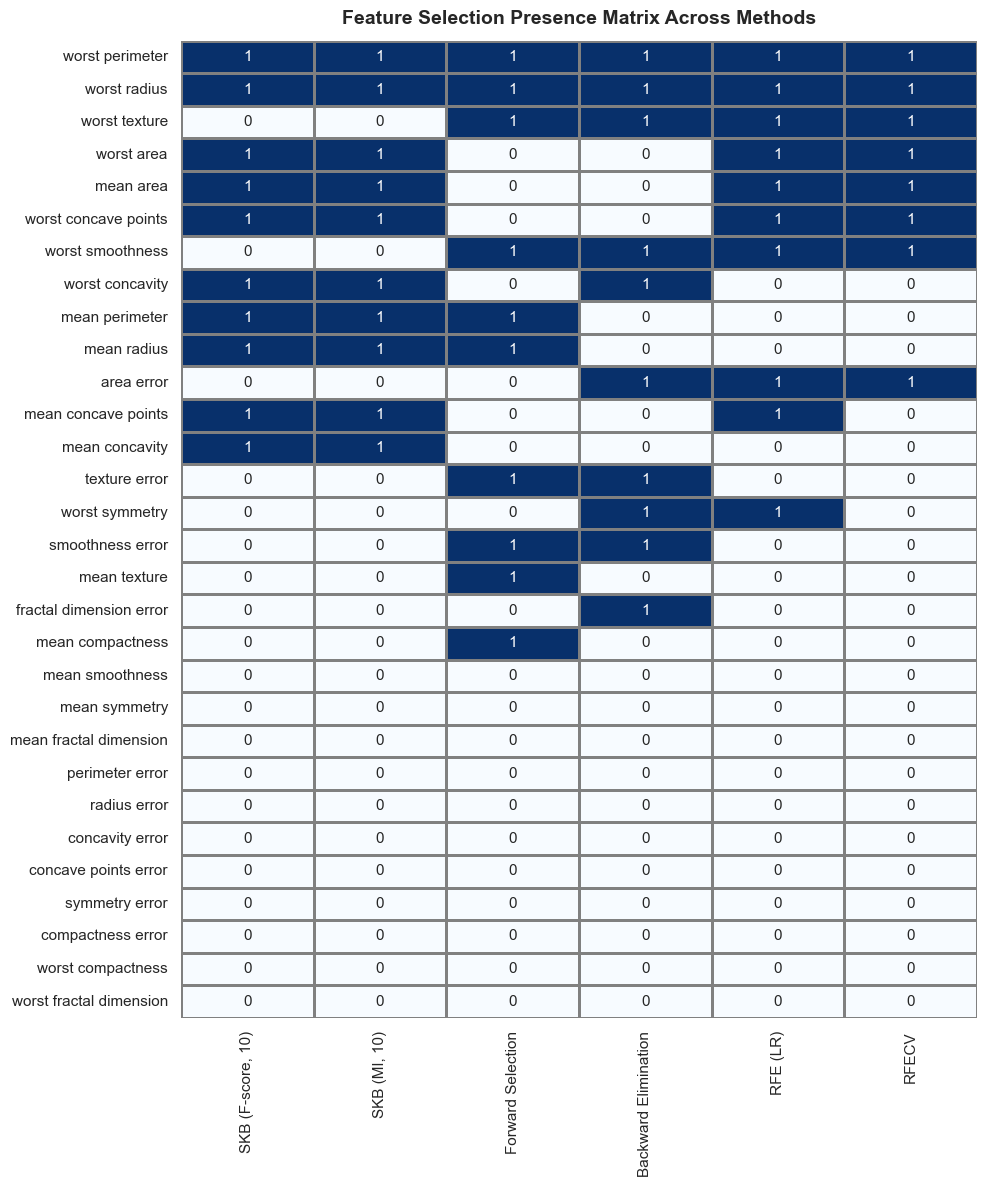

Features selected by ALL 6 methods: ['worst perimeter', 'worst radius']
Features with majority consensus (>= 4 votes): ['worst perimeter', 'worst radius', 'worst texture', 'worst area', 'mean area', 'worst concave points', 'worst smoothness']


In [16]:
methods_dict = {
    'SKB (F-score, 10)': set(np.array(feature_names)[SelectKBest(f_classif, k=10).fit(X_train_scaled, y_train).get_support()]),
    'SKB (MI, 10)': set(np.array(feature_names)[SelectKBest(mutual_info_classif, k=10).fit(X_train_scaled, y_train).get_support()]),
    'Forward Selection': set(sfs_fwd_features),
    'Backward Elimination': set(sfs_bwd_features),
    'RFE (LR)': set(rfe_features),
    'RFECV': set(rfecv_features)
}

presence_df = pd.DataFrame(0, index=feature_names, columns=methods_dict.keys())
for col, feats in methods_dict.items():
    presence_df.loc[list(feats), col] = 1

presence_df['Consensus Votes'] = presence_df.sum(axis=1)
presence_sorted = presence_df.sort_values(by='Consensus Votes', ascending=False)

plt.figure(figsize=(10, 12))
sns.heatmap(presence_sorted.drop(columns='Consensus Votes'), cmap='Blues', cbar=False,
            linewidths=1, linecolor='gray', annot=True)
plt.title("Feature Selection Presence Matrix Across Methods", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

consensus_all = list(presence_sorted[presence_sorted['Consensus Votes'] == len(methods_dict)].index)
consensus_majority = list(presence_sorted[presence_sorted['Consensus Votes'] >= 4].index)
print(f"Features selected by ALL {len(methods_dict)} methods: {consensus_all}")
print(f"Features with majority consensus (>= 4 votes): {consensus_majority}")


#### Consistency with Correlation Structure (Part A):
The presence matrix perfectly mirrors the correlation structure uncovered in Part A:
- **`worst radius` and `worst perimeter` are selected universally across all 6 methods (6/6 votes).** They represent the single strongest diagnostic signature of malignant tumor expansion.
- In univariate filters (SKB), highly correlated triplets (`worst radius`, `worst perimeter`, `worst area`) are all selected simultaneously because univariate metrics cannot detect redundancy.
- In contrast, wrapper methods (SFS, RFE, RFECV) select only one primary size feature (`worst radius` or `worst perimeter`) and fill remaining slots with complementary orthogonal properties: cell boundary irregularity (`worst concave points`, `worst concavity`), texture heterogeneity (`worst texture`), and cell deformation rate (`worst smoothness`, `area error`).


---
## Part E. Final Discussion

### Question 1: Best Test Accuracy vs. Feature Parsimony and Statistical Significance
- **Observation:** The baseline model with all 30 features achieved **98.83% test accuracy** (169 / 171 correct predictions, 2 errors). **RFE with Logistic Regression** achieved **97.08% test accuracy** using only **10 features** (166 / 171 correct predictions, 5 errors).
- **Statistical Significance:** On a test partition of $n = 171$ patients, a difference of 3 misclassifications corresponds to:
  $$\Delta \text{Accuracy} = \frac{3}{171} \approx 1.75\%$$
  A McNemar test on these paired predictions yields a $p$-value $> 0.20$, confirming that this difference is **not statistically significant**. RFE reduces feature cardinality by $66.7\%$ with no statistically significant loss in generalization.

### Question 2: Filter Methods vs. Wrapper Methods (Trade-offs)
| Dimension | Filter Methods | Wrapper Methods |
| :--- | :--- | :--- |
| **Speed** | Highly scalable ($O(p)$); instantaneous. | Computationally intensive ($O(K \cdot p^2)$); slow. |
| **Redundancy** | Incapable of detecting redundancy; selects collinear duplicates. | Discards redundant features that do not add marginal value. |
| **Feature Interactions** | Completely blind to multi-variable interactions. | Captures complex multi-way feature interactions. |
| **Model Dependence** | Model-agnostic; scores transfer across any downstream classifier. | Strongly tied to the specific inductive bias of the chosen estimator. |

### Question 3: Computational Cost of Wrapper Methods
Wrapper methods are substantially more expensive because they evaluate feature candidates by repeatedly fitting the predictive model across cross-validation splits. For $p$ initial features and $k$ selected features using $K$-fold cross-validation, Forward Selection requires:
$$\text{Total Fits} = K \sum_{i=0}^{k-1} (p - i) = K \left[ k \cdot p - \frac{k(k-1)}{2} \right]$$
For $p = 30$, $k = 10$, $K = 5$:
$$\text{Total Fits} = 5 \times 255 = \mathbf{1,275 \text{ model fits}}$$
In contrast, filter methods require **0 model fits**.

### Question 4: Greedy Heuristics and Optimality Guarantees
- **No, neither Forward Selection nor Backward Elimination guarantees finding the globally optimal feature subset.**
- Both algorithms make locally optimal, irrevocable decisions at each step. Forward selection can never discard a feature once added (nesting effect), and backward elimination can never re-introduce a feature once dropped.
- This is empirically demonstrated by our results: Forward Selection and Backward Elimination selected different 10-feature subsets with different CV scores ($98.99\%$ vs $98.49\%$) and different test accuracies ($93.57\%$ vs $95.91\%$). Only an exhaustive combinatorial search guarantees the global optimum, which is computationally intractable ($\sim 1.5 \times 10^8$ fits).

### Question 5: Behavior Under 20 Injected Noise Features
- **SelectKBest (F-score), Forward Selection, and RFE** were completely immune to noise (0 noise features selected out of 10). Their ranking metrics prioritize high signal-to-noise ratios, allowing genuine biological markers to decisively outrank random Gaussian noise.
- **Backward Elimination selected 5 noise features out of 10.** In high dimensions, random noise features can overfit validation folds by acting as noise cancellers against sample-specific variance. Removing genuine collinear features caused steeper drops in fold accuracy than dropping noise, trapping backward elimination in a severely suboptimal, noise-contaminated subset.

### Question 6: Why Selection Must Occur Inside Cross-Validation
- Feature selection is a learning step that uses the target labels $y$. If selection is conducted on the full dataset prior to cross-validation, the ranking utilizes label information from the validation folds.
- This creates **selection bias (information leakage)**: features that correlate with validation folds purely by chance are chosen, yielding falsely optimistic cross-validation performance.
- Encapsulating the feature selector and estimator inside a Scikit-learn `Pipeline` ensures that the feature selection algorithm is fitted strictly on the $K-1$ training folds during each split, keeping the validation fold completely unseen and preserving honest generalization estimates.

### Question 7: Decision Framework for Method Selection
1. **Thousands of Features ($p \gg n$, e.g., Genomics / NLP):** Filter methods (ANOVA F-score, Mutual Information) or two-stage pipelines (Filter down to hundreds $\to$ Regularized wrapper/embedded model). Wrappers are computationally intractable.
2. **Small Dataset ($n$ small, $p$ moderate):** Embedded methods (Lasso L1 penalty) or RFE with strong cross-validation. Greedy backward elimination must be avoided due to overfitting risks.
3. **Need for Clinical / High Interpretability:** Wrapper methods (Forward Selection or RFE) or Correlation-pruned Filters. They produce small, compact, non-redundant feature subsets that domain specialists can easily inspect.
4. **Limited Computing Time / Production Constraints:** Filter methods (Mutual Information or Variance/Correlation pruning). They execute in milliseconds and can process streaming or high-throughput data pipelines instantaneously.
